<a href="https://colab.research.google.com/github/p2ms/Modelos_ML/blob/main/Analise_de_Investimentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instalação e inicialização das bilbiotecas

In [4]:
pip install scikit-learn numpy pandas seaborn matplotlib

In [5]:
## Importando bibliotecas

import numpy as np # calculos numericos
import pandas as pd # manipulacao de dados
import matplotlib.pyplot as plt # visualizacao de dados
import seaborn as sns # visualizaçaõ de dados

#machine learning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error

# definição de tema padrão para graficos
sns.set_theme(style="whitegrid", palette="Set2")




# Carregamento de dados
Importar os dados necessarios para a simulação dos investimentos



,Ano,Proventos Recebidos (R$)
0,2020,80.03
1,2021,1923.98
2,2022,2211.20
3,2023,2583.78
4,2024,3201.45
5,2025,4419.13
6,2026,2652.87


<Axes: xlabel='Ano'>

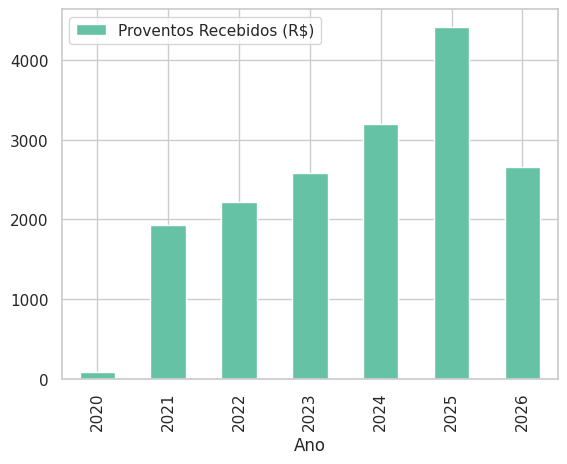

In [8]:
#Ler planilha axcel e converter para um dataframe (df)
df = pd.read_excel("/content/2020_2026_proventos_anuais.xlsx")

#Visualizar dados (tabela)
display(df)

#Visualizar dados (gráfico)
df.plot(kind="bar", x="Ano")

# Limpeza dos dados
Limpar os anos 2020 (quantidade muito pequena, dado não representativo) e 2026 (o ano ainda não terminou, logo tbm é um dado não representativo)

[Amostra de treino]

,Ano,Proventos Recebidos (R$)
1,2021,1923.98
2,2022,2211.20
3,2023,2583.78
4,2024,3201.45
5,2025,4419.13


<Axes: xlabel='Ano'>

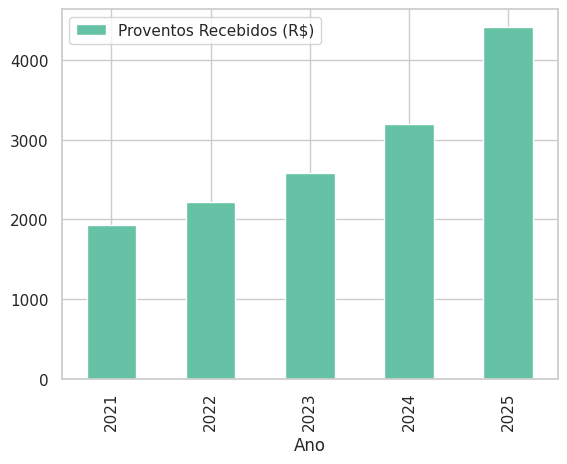

In [9]:
df_treino = df[(df["Ano"] >= 2021) & (df["Ano"] <= 2025)] # cria um filtro duplo

# visualizar os dados (tabela)
display(df_treino)

#visualizar os dados (grafico)
df_treino.plot(kind="bar", x="Ano")


# Regressão Linear

modelo mais simples porem muito eficaz.

In [10]:
# criando a regressão

#Separação de variaveis
x = df_treino[["Ano"]] # variavel preditora / variavel independente / feature / x
y = df_treino[["Proventos Recebidos (R$)"]] # variavel prevista / variavel dependente / target / y

#criando modelo de regressão linear
modelo_linear = LinearRegression()

# treinando modelo com dados históricos
# modelo de aprendizado SUPERVISIONADO -> contem variavel y (dados reais do passado)
modelo_linear.fit(x, y) #.fit ==>

# fazendo previsões para o histórico analisado (2021 - 2025)
prev_historico_linear = modelo_linear.predict(x)

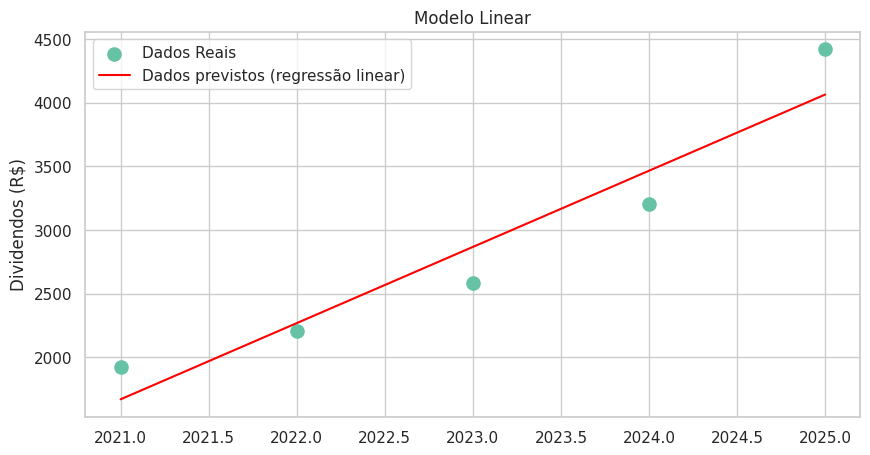

In [11]:
## Visualização da regressão

plt.figure(figsize=(10, 5))

#pontos representando os valores reais
plt.scatter(
    x, # anos
    y, #dados reais
    s = 90,
    label = "Dados Reais"
)
plt.plot(
    x, #anos
    prev_historico_linear, #dados previstos
    color = "red",
    label = "Dados previstos (regressão linear)"
)
plt.title("Modelo Linear")
plt.ylabel("Dividendos (R$)")
plt.legend()
plt.show()

Avaliando o modelo de regressão (parte crucial da analise, so a visualização não é eficiente)

In [12]:
# avaliação do modelo a partir de métricas

## referencias: 1. como criar um modelo de previsao com ML 2. como avaliar um modelo de ML

#mede a variancia total explicada pelo modelo (ratio) --> quanto mais prox do 1 melhor a predição
r2_linear = r2_score(y, prev_historico_linear)
print(f"R² (coeficiente de determinação): {r2_linear:.3f}")

# erro médio do modelo em valores percentuais (%)
mape_linear = mean_absolute_percentage_error(y, prev_historico_linear) * 100
print(f"MAPE (erro médio percentual absoluto): {mape_linear:.2f}%")

#erro quadratico do modelo (penaliza erros grandes) na unidade dos dados (R$)
rmse_linear = root_mean_squared_error(y, prev_historico_linear)
print(f"RMSE (erro médio quadrático): R${rmse_linear:.2f}")

R² (coeficiente de determinação): 0.912
MAPE (erro médio percentual absoluto): 8.61%
RMSE (erro médio quadrático): R$262.24


## Regressão Exponencial

In [13]:
# criando a regressão exponencial (avalia melhor os valores do mercado financeiro -- considera os juros compostos do investimento)
## transformação logaritmica
y_log = np.log(y)


#criando modelo exponencial (nao-linear)
modelo_exp = LinearRegression()

# treinando modelo com dados históricos
# modelo de aprendizado SUPERVISIONADO -> contem variavel y (dados reais do passado)
modelo_exp.fit(x, y_log) #.fit ==>

# fazendo previsões para o histórico analisado (2021 - 2025)
prev_historico_exp = np.exp(modelo_exp.predict(x)) #pra reverter o log que foi colocado para y

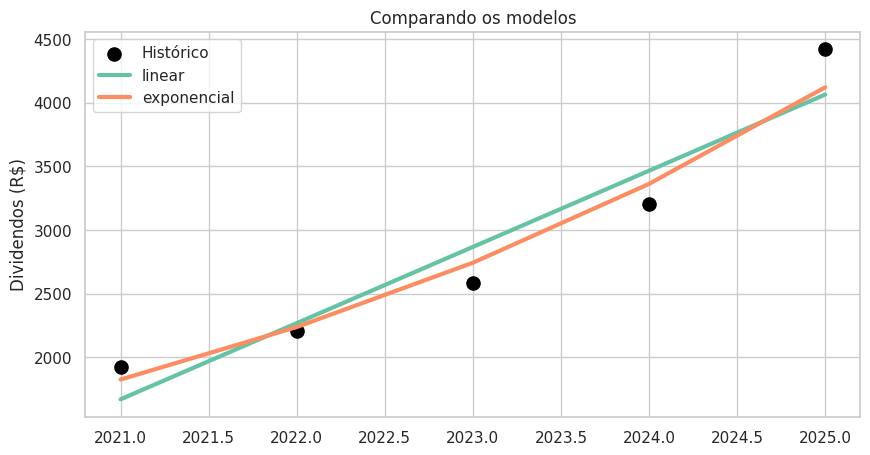

In [15]:
## Visualização da regressão

plt.figure(figsize=(10, 5))

#pontos representando os valores reais
plt.scatter( #scatter ==> as bolinhas do grafico
    x, # anos
    y, #dados reais
    s = 90,
    color = "black",
    label = "Histórico"
)
#previsões lineares
plt.plot(
    x, #anos
    prev_historico_linear, #dados previstos
    linewidth = 3,
    label = "linear"
)
#previsões nao-lineares
plt.plot(
    x, #anos
    prev_historico_exp, #dados previstos
    linewidth = 3,
    label = "exponencial"
)
plt.legend()
plt.title("Comparando os modelos")
plt.ylabel("Dividendos (R$)")
plt.show()

In [16]:
# avaliação do modelo a partir de métricas

## referencias: 1. como criar um modelo de previsao com ML 2. como avaliar um modelo de ML

#mede a variancia total explicada pelo modelo (ratio) --> quanto mais prox do 1 melhor a predição
r2_exp = r2_score(y, prev_historico_exp)
print(f"R² (coeficiente de determinação): {r2_exp:.3f}")

# erro médio do modelo em valores percentuais (%)
mape_exp = mean_absolute_percentage_error(y, prev_historico_exp) * 100
print(f"MAPE (erro médio percentual absoluto): {mape_exp:.2f}%")

#erro quadratico do modelo (penaliza erros grandes) na unidade dos dados (R$)
rmse_exp = root_mean_squared_error(y, prev_historico_exp)
print(f"RMSE (erro médio quadrático): R${rmse_exp:.2f}")

R² (coeficiente de determinação): 0.962
MAPE (erro médio percentual absoluto): 4.85%
RMSE (erro médio quadrático): R$173.70


# Previsões

In [17]:
# criando o dataframe dos ano
futuro = pd.DataFrame({
    "Ano": [2026, 2027, 2028, 2029, 2030]
})
display(futuro)

,Ano
0,2026
1,2027
2,2028
3,2029
4,2030


,Ano,Linear,Exponencial
0,2026,4662.073,5049.528950
1,2027,5260.128,6187.995384
2,2028,5858.183,7583.140380
3,2029,6456.238,9292.834665
4,2030,7054.293,11387.996502


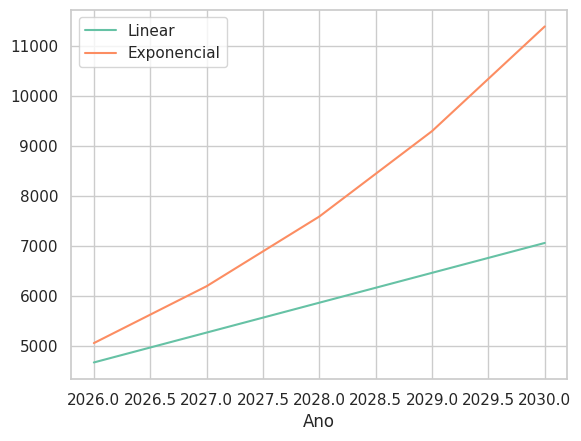

In [20]:
prev_futuro_linear = modelo_linear.predict(futuro[["Ano"]])

#add as previsões no dataFrame criado
futuro["Linear"] = prev_futuro_linear

#fazendo o mesmo com o modelo exponencial
prev_futuro_exp = np.exp(modelo_exp.predict(futuro[["Ano"]]))
futuro["Exponencial"] = prev_futuro_exp

#visualização (tabela)
display(futuro)

# visualização (grafico)
futuro.plot(x="Ano")
plt.show()


In [21]:
# quanto de renda passiva vai receber por mes
futuro["Exponencial"] /12

,Exponencial
0,420.794079
1,515.666282
2,631.928365
3,774.402889
4,948.999709
